# 08 - Política de pico e pontos de coleta

O notebook 07 sugeriu uma política: **margem de 5 min, espera máxima de 5 min fora do pico e nenhuma espera no pico**. E deixou uma dúvida: o modelo usa **um hub por cidade**, mas na vida real cada restaurante é um ponto de coleta.

**Perguntas**
1. Não esperar no pico custa quanto de economia - e quanto de prazo devolve?
2. Se a coleta for no **bairro de origem** (restaurantes agrupados por bairro), em vez de um hub por cidade, a economia se mantém?

Mesmas regras do notebook 07 (`simular_despacho` em `roteirizacao/despacho.py`), margem de 5 min, até 4 pedidos por moto. Cada cenário é comparado com as viagens individuais **do mesmo modelo de coleta e volume**.

## 1. Configuração e cenários

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.ingestao.simulacao import gerar_entregas
from logistica_rotas.roteirizacao.despacho import resumo_despacho, simular_despacho
from logistica_rotas.visualizacao import graficos as g

volumes = {"atual": df, "4x": gerar_entregas(n=20_000)}
politicas = {"espera 5 min sempre": {}, "sem espera no pico": {"espera_max_pico_min": 0}}
linhas = []
for nome_volume, base in volumes.items():
    for coleta in ["hub", "bairro"]:
        individual = resumo_despacho(simular_despacho(base, 0, capacidade=1, ponto_coleta=coleta))
        linhas.append({"volume": nome_volume, "coleta": coleta, "politica": "individual",
                       **individual.to_dict(), "economia_km_pct": 0.0})
        for nome, extra in politicas.items():
            r = resumo_despacho(simular_despacho(base, 5, 4, 5, ponto_coleta=coleta, **extra), individual["km"])
            linhas.append({"volume": nome_volume, "coleta": coleta, "politica": nome, **r.to_dict()})
cenarios = pd.DataFrame(linhas)
cenarios[["volume", "coleta", "politica", "entregas_por_viagem", "economia_km_pct", "espera_media_min",
          "no_prazo_plan_pct", "no_prazo_real_pct"]]

,volume,coleta,politica,entregas_por_viagem,economia_km_pct,espera_media_min,no_prazo_plan_pct,no_prazo_real_pct
0,atual,hub,individual,1.0,0.0,0.0,98.4,97.0
1,atual,hub,espera 5 min sempre,1.1,2.0,4.3,98.4,95.3
2,atual,hub,sem espera no pico,1.1,1.9,3.6,98.4,96.4
3,atual,bairro,individual,1.0,0.0,0.0,99.5,98.1
4,atual,bairro,espera 5 min sempre,1.0,0.4,4.7,99.5,96.6
5,atual,bairro,sem espera no pico,1.0,0.4,4.0,99.5,97.6
6,4x,hub,individual,1.0,0.0,0.0,98.3,97.0
7,4x,hub,espera 5 min sempre,1.2,6.2,3.7,98.3,94.8
8,4x,hub,sem espera no pico,1.2,5.7,3.1,98.3,95.3
9,4x,bairro,individual,1.0,0.0,0.0,99.5,98.0


## 2. Comparação

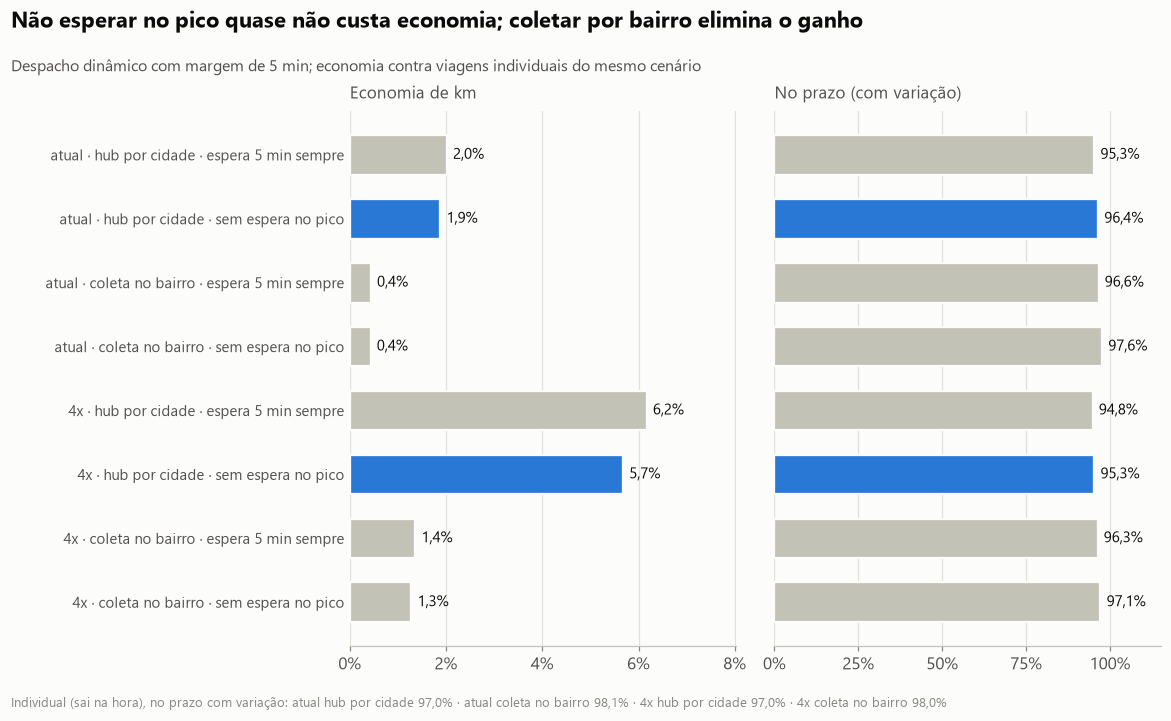

In [2]:
NOME_COLETA = {"hub": "hub por cidade", "bairro": "coleta no bairro"}
tabela = cenarios[cenarios["politica"] != "individual"].copy()
tabela["cenario"] = tabela["volume"] + " · " + tabela["coleta"].map(NOME_COLETA) + " · " + tabela["politica"]
tabela = tabela.set_index("cenario")
destaques = [c for c in tabela.index if "hub por cidade · sem espera no pico" in c]
ind = cenarios[cenarios["politica"] == "individual"].set_index(["volume", "coleta"])["no_prazo_real_pct"]
nota = "Individual (sai na hora), no prazo com variação: " + " · ".join(
    f"{v} {NOME_COLETA[c]} {p:.1f}%".replace(".", ",") for (v, c), p in ind.items())
fig = g.barras_cenarios(tabela, destaques,
                        "Não esperar no pico quase não custa economia; coletar por bairro elimina o ganho",
                        "Despacho dinâmico com margem de 5 min; economia contra viagens individuais do mesmo cenário",
                        nota)
g.salvar_figura(fig, "14_politicas_e_coleta");

**Leitura:**
- **Sem espera no pico, a troca é boa.** No volume atual, a economia passa de 2,0% para 1,9% e as entregas no prazo (com variação) sobem de 95,3% para 96,4%, contra 97,0% saindo na hora. Com 4 vezes o volume, a economia vai de 6,2% para 5,7% e o prazo de 94,8% para 95,3%. No pico a espera rendia quase nada (notebook 07), então cortá-la só devolve prazo.
- **Coletar por bairro elimina o ganho.** Com um ponto de coleta por bairro, só pedidos do mesmo bairro de origem podem dividir a moto, e eles raramente chegam juntos. A economia cai para 0,4% (atual) e 1,3% (4x) com a política sem espera no pico, enquanto a espera continua custando prazo.
- **A consolidação depende de centralizar a coleta.** O ganho de agrupar entregas existe quando muitos pedidos saem do mesmo lugar (um hub, uma dark kitchen ou um centro de distribuição). Com restaurantes espalhados, o agrupamento simples não compensa: seria preciso um modelo com várias coletas na mesma viagem.

## 3. Conclusões

1. **Política recomendada (com hub):** margem de 5 min, espera de até 5 min fora do pico e nenhuma espera no pico. No volume atual, ela economiza 1,9% dos km e perde só 0,6 ponto de prazo na rua; com 4 vezes o volume, 5,7% e 1,7 ponto.
2. **Sem hub, não agrupar.** Com coleta espalhada por bairro, a economia fica abaixo de 1,5% mesmo com 4 vezes o volume. Melhor despachar na hora.
3. **Para o negócio:** o ganho de roteirização vem da **centralização da coleta** e do **volume**, não do algoritmo. Um hub ou dark kitchen por cidade é o que cria oportunidade de agrupar pedidos.

**Limitações:** coleta em vários pontos na mesma viagem (pickup and delivery) não foi modelada; frota ilimitada; tempos simulados.